# 💊 Medicine Label Cognitive Assistant (Jupyter version)
**LandingLens object detection + OCR + Text-to-Speech**

1. Image of a medicine bottle / strip / box
2. LandingLens model detects the text lines on the label
3. OCR reads each detected line
4. Parser extracts name, strength, expiry, batch, dosage, warnings and checks expiry
5. Assistant shows a report and **speaks** the result

**Before running:** put your test image (e.g. `test_label_valid.jpg`) in the same folder as this notebook, and paste your Endpoint ID in the Configuration cell. You'll be asked for your API key when that cell runs.

In [1]:
%pip install -q landingai pillow matplotlib gTTS easyocr python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import getpass
import os
import re
from datetime import date

import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Audio
from gtts import gTTS
from landingai.predict import Predictor

## 1. Configuration

In [4]:
from dotenv import load_dotenv
load_dotenv("a.env")

API_KEY = os.environ.get("LANDINGAI_API_KEY") or getpass.getpass("LandingAI API key: ")
ENDPOINT_ID = os.environ.get("LANDINGAI_ENDPOINT_ID")

In [5]:

USE_DETECTOR = True

DETECTION_THRESHOLD = 0.25
LOW_OCR_CONFIDENCE = 0.50

detector = Predictor(endpoint_id=ENDPOINT_ID, api_key=API_KEY) if USE_DETECTOR else None
print("Detector ready." if detector else "Running in OCR-only mode.")

Detector ready.


## 2. Label-region detection (LandingLens)

In [6]:
def detect_label_regions(image):
    """Returns list of (class_name, score, (x0, y0, x1, y1))."""
    full = [("full_label", 1.0, (0, 0, image.width, image.height))]
    if detector is None:
        return full

    predictions = detector.predict(np.array(image))
    print("\nRaw detector predictions:")
    print(predictions)

    regions = []
    for p in predictions:
        bbox = getattr(p, "bboxes", None)          # ObjectDetectionPrediction
        score = getattr(p, "score", 0.0)
        if bbox is None or score < DETECTION_THRESHOLD:
            continue
        regions.append((p.label_name, score, tuple(int(v) for v in bbox)))

    if not regions:
        print("No label regions detected; reading the whole image instead.")
        return full
    # pad boxes slightly so OCR doesn't clip letters, then sort top-to-bottom
    pad = 6
    regions = [(n, s, (max(0, x0 - pad), max(0, y0 - pad),
                       min(image.width, x1 + pad), min(image.height, y1 + pad)))
               for n, s, (x0, y0, x1, y1) in regions]
    regions.sort(key=lambda r: (r[2][1] // 20, r[2][0]))
    return regions


def draw_regions(image, regions):
    boxed = image.copy()
    draw = ImageDraw.Draw(boxed)
    for name, score, (x0, y0, x1, y1) in regions:
        draw.rectangle([x0, y0, x1, y1], outline="lime", width=3)
        draw.text((x0 + 4, max(0, y0 - 12)), f"{name} {score:.2f}", fill="lime")
    return boxed

## 3. OCR (LandingAI OCR, falls back to EasyOCR)

In [7]:
_easyocr_reader = None


def run_ocr(image):
    """Returns list of (text, confidence, (x0, y0, x1, y1))."""
    arr = np.array(image)
    try:
        from landingai.predict import OcrPredictor
        preds = OcrPredictor(api_key=API_KEY).predict(arr, mode="multi-text")
        results = []
        for p in preds:
            xs = [pt[0] for pt in p.location]
            ys = [pt[1] for pt in p.location]
            results.append((p.text, p.score, (min(xs), min(ys), max(xs), max(ys))))
        return results
    except Exception as e:
        global _easyocr_reader
        if _easyocr_reader is None:
            print("LandingAI OCR unavailable, using EasyOCR. Reason:", e)
            import easyocr
            _easyocr_reader = easyocr.Reader(["en"], gpu=False)
        results = []
        for box, text, conf in _easyocr_reader.readtext(arr):
            xs = [pt[0] for pt in box]
            ys = [pt[1] for pt in box]
            results.append((text, conf, (min(xs), min(ys), max(xs), max(ys))))
        return results


def read_regions(image, regions):
    """OCR every detected region. Returns {class_name: [lines]} and all OCR items."""
    texts, all_items = {}, []
    for name, _, (x0, y0, x1, y1) in regions:
        crop = image.crop((x0, y0, x1, y1))
        items = sorted(run_ocr(crop), key=lambda t: (t[2][1], t[2][0]))  # top-to-bottom
        texts.setdefault(name, []).extend(t[0] for t in items)
        all_items.extend(items)
    return texts, all_items

## 4. Field extraction and expiry check

In [8]:
MONTHS = {m: i for i, m in enumerate(
    ["JAN", "FEB", "MAR", "APR", "MAY", "JUN",
     "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"], start=1)}

DATE_PATTERN = r"([A-Z]{3,9}\.?\s*[-/,]?\s*\d{2,4}|\d{1,2}\s*[-/.]\s*\d{1,2}\s*[-/.]\s*\d{2,4}|\d{1,2}\s*[-/.]\s*\d{2,4})"


def parse_date(text):
    """Parses MM/YYYY, MM/YY, DD/MM/YYYY, 'AUG 2027', 'AUG.27' -> date(year, month, 1)."""
    s = text.upper().strip()
    m = re.search(r"(?:(\d{1,2})\s*[-/.]\s*)?(\d{1,2})\s*[-/.]\s*(\d{2,4})", s)
    if m:
        month, year = int(m.group(2)), int(m.group(3))
    else:
        m = re.search(r"([A-Z]{3})[A-Z]*\.?\s*[-/,]?\s*(\d{2,4})", s)
        if not m or m.group(1) not in MONTHS:
            return None
        month, year = MONTHS[m.group(1)], int(m.group(2))
    if year < 100:
        year += 2000
    if not 1 <= month <= 12:
        return None
    return date(year, month, 1)


def find_field(pattern, text):
    m = re.search(pattern, text, flags=re.IGNORECASE)
    return m.group(1).strip() if m else None


def lines_with(keywords, lines):
    return [ln for ln in lines if any(k in ln.lower() for k in keywords)]


def extract_fields(region_texts, ocr_items):
    all_lines = [ln for lines in region_texts.values() for ln in lines]
    full_text = " ".join(all_lines)

    # Medicine name: detector class if available, else tallest OCR text with letters
    name = " ".join(region_texts.get("medicine_name", [])) or None
    if not name:
        candidates = [t for t in ocr_items
                      if re.search(r"[A-Za-z]{3,}", t[0])
                      and not re.search(r"exp|mfg|mfd|batch|b\.?no|lot|rx", t[0], re.I)]
        if candidates:
            name = max(candidates, key=lambda t: t[2][3] - t[2][1])[0]

    expiry_text = (" ".join(region_texts.get("expiry_date", []))
                   or find_field(r"(?:EXP(?:IRY)?|EXPIRES|USE\s*BEFORE)\.?\s*(?:DATE)?\s*[:.\-]?\s*" + DATE_PATTERN, full_text))
    mfg_text = find_field(r"(?:MFG|MFD|MANUFACTURED)\.?\s*(?:DATE|ON)?\s*[:.\-]?\s*" + DATE_PATTERN, full_text)
    batch = (" ".join(region_texts.get("batch_no", []))
             or find_field(r"(?:B\.?\s*NO|BATCH(?:\s*NO)?|LOT)\.?\s*[:.\-]?\s*([A-Z0-9\-]{3,})", full_text))

    strengths = re.findall(r"\b\d+(?:\.\d+)?\s*(?:mg|mcg|µg|g|ml|IU|%)(?:\s*/\s*\d*\s*ml)?\b",
                           full_text, flags=re.IGNORECASE)
    strength = ", ".join(dict.fromkeys(s.strip() for s in strengths)) or None

    dosage = region_texts.get("dosage") or lines_with(
        ["take", "dose", "dosage", "times a day", "daily", "as directed", "every"], all_lines)
    warnings = region_texts.get("warning") or lines_with(
        ["warning", "caution", "keep out of reach", "do not", "store", "not for"], all_lines)

    return {
        "name": name,
        "strength": strength,
        "expiry_text": expiry_text,
        "expiry_date": parse_date(expiry_text) if expiry_text else None,
        "mfg_text": mfg_text,
        "batch": batch,
        "dosage": " ".join(dosage) if dosage else None,
        "warnings": " ".join(warnings) if warnings else None,
        "raw_text": full_text,
    }


def expiry_status(expiry):
    """Medicine is usable until the END of its expiry month."""
    if expiry is None:
        return "UNKNOWN"
    today = date.today()
    if (today.year, today.month) > (expiry.year, expiry.month):
        return "EXPIRED"
    months_left = (expiry.year - today.year) * 12 + expiry.month - today.month
    return "EXPIRING SOON" if months_left <= 3 else "VALID"

## 5. Spoken response

In [9]:
def speakable(text):
    replacements = {r"\bmg\b": " milligrams", r"\bmcg\b": " micrograms", r"\bml\b": " millilitres",
                    r"\bIU\b": " international units", r"%": " percent"}
    for pat, rep in replacements.items():
        text = re.sub(pat, rep, text, flags=re.IGNORECASE)
    return text


def build_speech(fields, status, low_confidence):
    parts = []
    if low_confidence:
        parts.append("The text is not clear. Please retake the photo in better light.")
    parts.append(f"This medicine is {fields['name']}." if fields["name"]
                 else "I could not read the medicine name.")
    if fields["strength"]:
        parts.append(f"Strength: {fields['strength']}.")
    if fields["expiry_date"]:
        parts.append(f"Expiry date: {fields['expiry_date'].strftime('%B %Y')}.")
    parts.append({
        "EXPIRED": "Warning! This medicine has expired. Do not use it.",
        "EXPIRING SOON": "This medicine will expire within three months.",
        "VALID": "This medicine is not expired.",
        "UNKNOWN": "I could not read the expiry date.",
    }[status])
    if fields["dosage"]:
        parts.append(f"Directions: {fields['dosage']}.")
    if fields["warnings"]:
        parts.append(f"Caution: {fields['warnings']}.")
    parts.append("Please confirm with a pharmacist before use.")
    return speakable(" ".join(parts))

## 6. The cognitive assistant

In [14]:
def medicine_label_assistant(image_path):
    print("Medicine Label Cognitive Assistant")

    # 1. Load image from disk
    if not os.path.exists(image_path):
        print("File not found:", image_path)
        return
    with Image.open(image_path) as img:
        image = img.convert("RGB").copy()

    # 2. Detect label regions with LandingLens
    regions = detect_label_regions(image)
    display(draw_regions(image, regions))

    # 3. Read text
    region_texts, ocr_items = read_regions(image, regions)
    if not ocr_items:
        print("No text found on the label.")
        return
    avg_conf = float(np.mean([t[1] for t in ocr_items]))
    low_confidence = avg_conf < LOW_OCR_CONFIDENCE
    print(f"\nOCR lines: {len(ocr_items)} | average confidence: {avg_conf:.2f}")

    # 4. Understand the label
    fields = extract_fields(region_texts, ocr_items)
    status = expiry_status(fields["expiry_date"])

    icon = {"EXPIRED": "⛔", "EXPIRING SOON": "⚠️", "VALID": "✅", "UNKNOWN": "❓"}[status]
    report = f"""
### Assistant response: {icon} **{status}**

| Field | Value |
|---|---|
| Medicine name | {fields['name'] or '—'} |
| Strength | {fields['strength'] or '—'} |
| Expiry | {fields['expiry_text'] or '—'} |
| Manufactured | {fields['mfg_text'] or '—'} |
| Batch no. | {fields['batch'] or '—'} |
| Directions | {fields['dosage'] or '—'} |
| Warnings | {fields['warnings'] or '—'} |

<details><summary>Raw OCR text</summary>

{fields['raw_text']}
</details>
"""
    if low_confidence:
        report += "\n> ⚠️ Low OCR confidence — retake the photo with better lighting and focus."
    display(Markdown(report))

    # 5. Speak the result
    speech_text = build_speech(fields, status, low_confidence)
    print("\nSpoken response:", speech_text)
    gTTS(text=speech_text, lang="en").save("medicine_response.mp3")
    display(Audio("medicine_response.mp3", autoplay=False))
    print("Audio saved as medicine_response.mp3")
    base = os.path.splitext(os.path.basename(image_path))[0]
    draw_regions(image, regions).save(f"{base}_detected.jpg")
    with open(f"{base}_report.md", "w", encoding="utf-8") as f:
        f.write(report + "\n\n**Spoken response:** " + speech_text + "\n")
    os.replace("medicine_response.mp3", f"{base}_response.mp3")
    print(f"Saved: {base}_detected.jpg, {base}_report.md, {base}_response.mp3")

## 7. Run the assistant
Change the file name to test another image.

Medicine Label Cognitive Assistant

Raw detector predictions:
[ObjectDetectionPrediction(score=0.8614099621772766, label_name='medicine-label', label_index=1, id='8cb6ca82-0298-47d0-90a9-e86bed0c1439', bboxes=(268, 406, 709, 457)), ObjectDetectionPrediction(score=0.8589447736740112, label_name='medicine-label', label_index=1, id='7696dd18-f438-4fec-8541-b020f479139c', bboxes=(534, 1000, 751, 1042)), ObjectDetectionPrediction(score=0.8073495626449585, label_name='medicine-label', label_index=1, id='5694d19e-61ce-4919-a624-538cc78f5d3d', bboxes=(324, 581, 674, 625)), ObjectDetectionPrediction(score=0.8001275062561035, label_name='medicine-label', label_index=1, id='85b039c3-dc80-4fea-8eb0-250cadc8ac88', bboxes=(247, 884, 687, 929)), ObjectDetectionPrediction(score=0.7174216508865356, label_name='medicine-label', label_index=1, id='5d142d07-07ec-4000-9e5d-c07effa2d86e', bboxes=(260, 1062, 661, 1098)), ObjectDetectionPrediction(score=0.7056830525398254, label_name='medicine-label', label_i

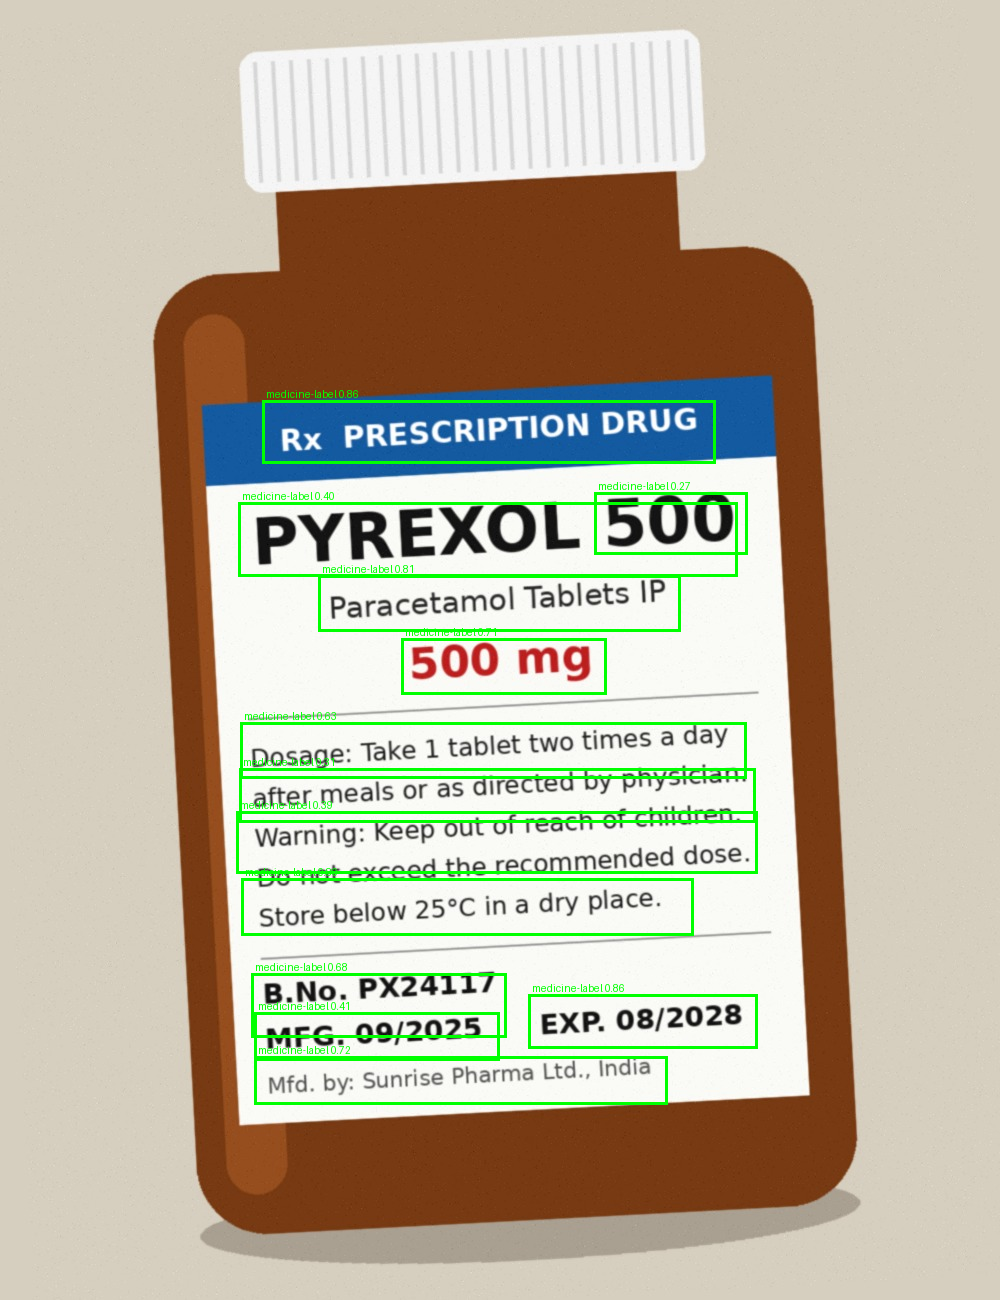


OCR lines: 15 | average confidence: 0.98



### Assistant response: ✅ **VALID**

| Field | Value |
|---|---|
| Medicine name | PYREXOL |
| Strength | 500mg |
| Expiry | 08/2028 |
| Manufactured | 09/2025 |
| Batch no. | PX24117 |
| Directions | Dosage:Take1tablettwotimesaday mmendeddose. |
| Warnings | Warning:Keepoutofreac Storebelow25°Cinadryplace |

<details><summary>Raw OCR text</summary>

RX PRESCRIPTIONDRUG 500 PYREXOL ParacetamolTabletsIp 500mg Dosage:Take1tablettwotimesaday aftermealsorasdirectedby Warning:Keepoutofreac mmendeddose. Storebelow25°Cinadryplace B.No.PX24117 09/2025 EXP.08/2028 MFG.09/2025 Mfd.by:Sunrise Pharma Ltd.,India
</details>



Spoken response: This medicine is PYREXOL. Strength: 500mg. Expiry date: August 2028. This medicine is not expired. Directions: Dosage:Take1tablettwotimesaday mmendeddose.. Caution: Warning:Keepoutofreac Storebelow25°Cinadryplace. Please confirm with a pharmacist before use.


Audio saved as medicine_response.mp3
Saved: test_label_valid_detected.jpg, test_label_valid_report.md, test_label_valid_response.mp3


In [18]:
medicine_label_assistant("test_label_valid.jpg")

Expired example:

Medicine Label Cognitive Assistant

Raw detector predictions:
[ObjectDetectionPrediction(score=0.8739321231842041, label_name='medicine-label', label_index=1, id='ed27af81-825a-4bc3-85f4-a3430bf5bc9f', bboxes=(268, 406, 709, 456)), ObjectDetectionPrediction(score=0.8395090103149414, label_name='medicine-label', label_index=1, id='9933e504-788b-4aa8-9df6-36c1aca126be', bboxes=(534, 1000, 750, 1041)), ObjectDetectionPrediction(score=0.8191213607788086, label_name='medicine-label', label_index=1, id='082a0fe2-19a9-425b-822d-5eb3a2e3d6c6', bboxes=(248, 884, 687, 930)), ObjectDetectionPrediction(score=0.781597912311554, label_name='medicine-label', label_index=1, id='8c32db23-c755-4e92-80b2-3875ef46838a', bboxes=(318, 581, 675, 625)), ObjectDetectionPrediction(score=0.719076931476593, label_name='medicine-label', label_index=1, id='6eba974a-4d9c-43c1-9db7-5d56b4d3f336', bboxes=(259, 1062, 659, 1098)), ObjectDetectionPrediction(score=0.69501793384552, label_name='medicine-label', label_index

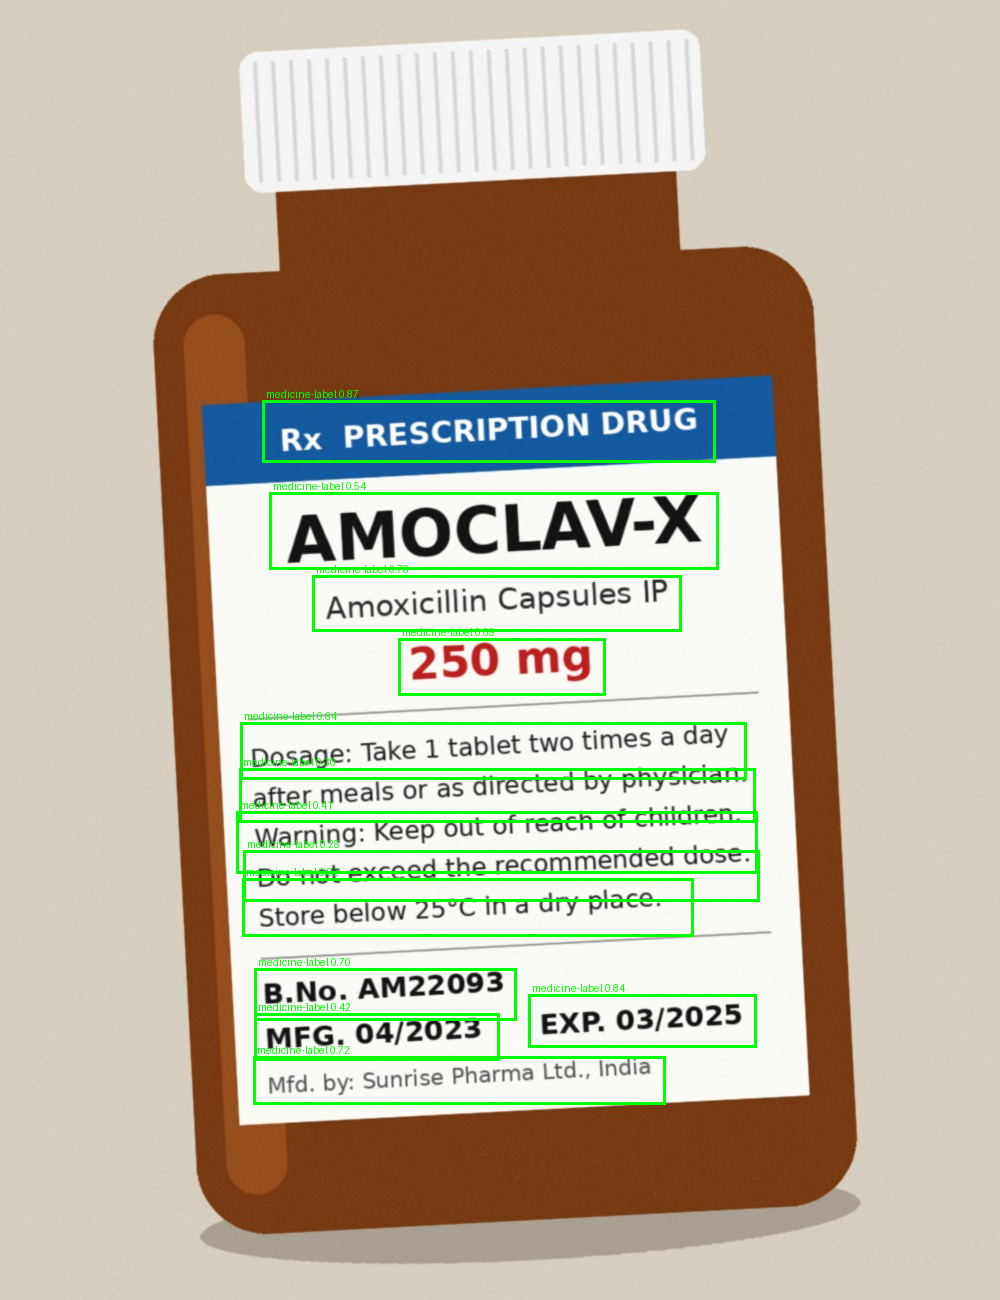


OCR lines: 14 | average confidence: 0.98



### Assistant response: ⛔ **EXPIRED**

| Field | Value |
|---|---|
| Medicine name | AMOCLAV-X |
| Strength | 250mg |
| Expiry | 03/2025 |
| Manufactured | 04/2023 |
| Batch no. | — |
| Directions | Dosage:Take1tablettwotimesaday ommendeddose. |
| Warnings | Warning:Keepoutofreac Storebelow25°Cinadryplace |

<details><summary>Raw OCR text</summary>

RXPRESCRIPTIONDRUG AMOCLAV-X AmoxicillinCapsulesIP 250mg Dosage:Take1tablettwotimesaday aftermealsorasdirectedby Warning:Keepoutofreac ommendeddose. Donotexceedtherecommen Storebelow25°Cinadryplace B.N0.AM22093 EXP.03/2025 MFG.04/2023 Mfd.by:Sunrise Pharma Ltd.,India
</details>



Spoken response: This medicine is AMOCLAV-X. Strength: 250mg. Expiry date: March 2025. Warning! This medicine has expired. Do not use it. Directions: Dosage:Take1tablettwotimesaday ommendeddose.. Caution: Warning:Keepoutofreac Storebelow25°Cinadryplace. Please confirm with a pharmacist before use.


Audio saved as medicine_response.mp3
Saved: test_label_expired_detected.jpg, test_label_expired_report.md, test_label_expired_response.mp3


In [19]:
medicine_label_assistant("test_label_expired.jpg")